# Redes Convolucionais com PyTorch: LeNet-5 e ResNet18 pré-treinada

No notebook 7, vimos as peças do treino de uma rede no PyTorch: tensores, batches, `DataLoader`, loss, otimizador e o loop de cinco passos. Este notebook usa essas mesmas peças com **imagens**, seguindo o tutorial clássico do PyTorch *Training a Classifier*, que classifica as imagens do dataset CIFAR-10.

O roteiro é curto:

1. **Os dados**: imagens como tensores de shape (batch, canais, altura, largura).
2. **LeNet-5**: a rede do fim dos slides de redes convolucionais, treinada do zero.
3. **ResNet18 pré-treinada**: aproveitar uma rede treinada no ImageNet e só ajustá-la ao nosso problema (*transfer learning*).

O loop de treinamento é o mesmo do notebook 7. O que muda é o modelo e os dados.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as T
from torch.utils.data import DataLoader, Subset

%matplotlib inline
torch.manual_seed(42)

# Usa a GPU se houver: "cuda" (NVIDIA, ex.: Google Colab) ou "mps" (Mac com chip Apple)
if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"
print("Dispositivo:", device)

Dispositivo: cuda


Redes convolucionais fazem muitas contas, e uma GPU acelera bastante o treino. A variável `device` diz onde as contas vão acontecer; o modelo e cada batch precisam estar no mesmo dispositivo, o que fazemos com `.to(device)`. Sem GPU, o notebook roda na CPU, só que mais devagar (a parte da ResNet18 pode levar alguns minutos).

---
## 1. Os dados: CIFAR-10

O CIFAR-10 tem 60 mil imagens coloridas de $32 \times 32$ pixels, 50 mil de treino e 10 mil de teste, em 10 classes. O `torchvision` baixa o dataset (cerca de 170 MB) na primeira execução.

Cada imagem passa por duas transformações: `ToTensor()` converte a imagem em um tensor de shape $3 \times 32 \times 32$ (canais RGB, altura, largura) com valores entre 0 e 1, e `Normalize` padroniza cada canal para ficar em torno de zero, como fazíamos com as features em modelos anteriores.

In [2]:
transform = T.Compose([
    T.ToTensor(),
    T.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),   # (x - 0.5) / 0.5 em cada canal
])
train_set = torchvision.datasets.CIFAR10(root="./data", train=True, download=True, transform=transform)
test_set = torchvision.datasets.CIFAR10(root="./data", train=False, download=True, transform=transform)

classes = train_set.classes
print("Treino:", len(train_set), " Teste:", len(test_set))
print("Classes:", classes)

Treino: 50000  Teste: 10000
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


In [3]:
train_loader = DataLoader(train_set, batch_size=64, shuffle=True)
test_loader = DataLoader(test_set, batch_size=256, shuffle=False)

X_batch, y_batch = next(iter(train_loader))
print("Shape de X_batch:", tuple(X_batch.shape), "-> (batch, canais, altura, largura)")
print("Shape de y_batch:", tuple(y_batch.shape), "-> um rótulo inteiro (0 a 9) por imagem")

Shape de X_batch: (64, 3, 32, 32) -> (batch, canais, altura, largura)
Shape de y_batch: (64,) -> um rótulo inteiro (0 a 9) por imagem


O formato $(N, C, H, W)$ é o mesmo do slide *Following the shapes*: batch, canais, altura e largura. Repare que o target agora é um **inteiro** com a classe, e não um 0/1 como no notebook 7. Vamos ver algumas imagens do batch (desfazendo a normalização para exibir):

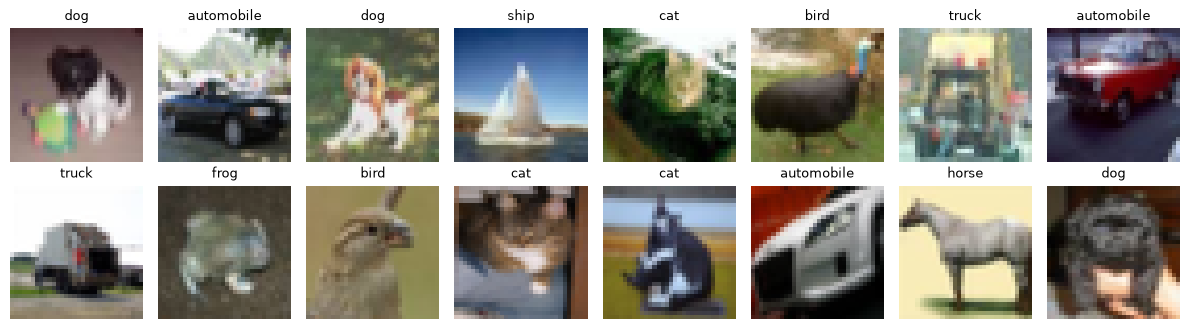

In [4]:
fig, axes = plt.subplots(2, 8, figsize=(12, 3.4))
for ax, img, rotulo in zip(axes.flat, X_batch, y_batch):
    img = img * 0.5 + 0.5                          # desfaz o Normalize
    ax.imshow(img.permute(1, 2, 0).numpy())        # (C, H, W) -> (H, W, C) para o matplotlib
    ax.set_title(classes[rotulo], fontsize=9)
    ax.axis("off")
plt.tight_layout(); plt.show()

---
## 2. LeNet-5

No fim dos slides, montamos uma rede no estilo LeNet-5 para dígitos em tons de cinza de $28 \times 28$. Para o CIFAR-10, só duas coisas mudam:

- a primeira convolução recebe **3 canais** (RGB) em vez de 1;
- a imagem tem $32 \times 32$, então a entrada da camada linear muda. Pela fórmula dos slides, $o = \frac{n - k + 2p}{s} + 1$: a convolução $5 \times 5$ leva $32 \to 28$, o pooling leva $28 \to 14$, a segunda convolução leva $14 \to 10$ e o segundo pooling leva $10 \to 5$. Com 16 mapas, o `Flatten` produz $16 \cdot 5 \cdot 5 = 400$ valores.

Seguindo a LeNet-5 original e o tutorial do PyTorch, colocamos também uma segunda camada oculta, de 84 neurônios.

In [5]:
def criar_lenet():
    return nn.Sequential(
        nn.Conv2d(3, 6, kernel_size=5),    # 3 canais (RGB) -> 6 mapas
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2),
        nn.Conv2d(6, 16, kernel_size=5),   # 6 -> 16 mapas
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2),
        nn.Flatten(),
        nn.Linear(16 * 5 * 5, 120),
        nn.ReLU(),
        nn.Linear(120, 84),
        nn.ReLU(),
        nn.Linear(84, 10),                 # 10 classes
    )

torch.manual_seed(42)
lenet = criar_lenet()
print("Parâmetros da LeNet-5:", sum(p.numel() for p in lenet.parameters()))

Parâmetros da LeNet-5: 62006


Uma forma prática de conferir as contas de shape é passar um batch pela rede **camada por camada** e imprimir o shape de cada saída. Este truque é muito usado na prática para depurar redes convolucionais.

In [6]:
h = X_batch[:4]                       # 4 imagens
print(f"{'entrada':12s} {tuple(h.shape)}")
for camada in lenet:
    h = camada(h)
    print(f"{camada.__class__.__name__:12s} {tuple(h.shape)}")

entrada      (4, 3, 32, 32)
Conv2d       (4, 6, 28, 28)
ReLU         (4, 6, 28, 28)
MaxPool2d    (4, 6, 14, 14)
Conv2d       (4, 16, 10, 10)
ReLU         (4, 16, 10, 10)
MaxPool2d    (4, 16, 5, 5)
Flatten      (4, 400)
Linear       (4, 120)
ReLU         (4, 120)
Linear       (4, 84)
ReLU         (4, 84)
Linear       (4, 10)


### 2.1 Treino e avaliação

O loop é o mesmo do notebook 7, com duas diferenças:

- **a loss**: com 10 classes, usamos `nn.CrossEntropyLoss`, a softmax loss dos slides. Assim como a `BCEWithLogitsLoss`, ela recebe as saídas da rede **sem** ativação (um score por classe) e aplica a softmax internamente; o target é o inteiro com a classe;
- **o dispositivo**: cada batch vai para `device` antes do forward pass.

Usamos também `model.train()` e `model.eval()`, que avisam à rede se ela está treinando ou sendo avaliada. Na LeNet isso não muda nada, mas na ResNet18 muda (ela tem camadas de *batch normalization*, que se comportam diferente nos dois modos), então é bom criar o hábito.

In [7]:
loss_fn = nn.CrossEntropyLoss()

def treinar_uma_epoca(model, loader, optimizer):
    model.train()
    soma_loss = 0.0
    for X_b, y_b in loader:
        X_b, y_b = X_b.to(device), y_b.to(device)
        loss = loss_fn(model(X_b), y_b)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        soma_loss += loss.item() * len(y_b)
    return soma_loss / len(loader.dataset)

@torch.no_grad()
def prever(model, loader):
    model.eval()
    preds, ys = [], []
    for X_b, y_b in loader:
        scores = model(X_b.to(device))          # um score por classe
        preds.append(scores.argmax(dim=1).cpu())  # classe de maior score
        ys.append(y_b)
    return torch.cat(preds), torch.cat(ys)

A previsão é a classe de **maior score**, `argmax`, que é a mesma de maior probabilidade depois da softmax. Agora treinamos por 10 épocas com SGD, como no tutorial (com `momentum`, uma variação do SGD que suaviza os passos usando a média dos gradientes recentes).

In [8]:
lenet = criar_lenet().to(device)
optimizer = torch.optim.SGD(lenet.parameters(), lr=0.01, momentum=0.9)

inicio = time.time()
for epoca in range(10):
    loss_treino = treinar_uma_epoca(lenet, train_loader, optimizer)
    pred, y_true = prever(lenet, test_loader)
    acc = (pred == y_true).float().mean().item()
    print(f"época {epoca + 1:2d}: loss treino = {loss_treino:.3f}, accuracy teste = {acc:.3f}")
tempo_lenet = time.time() - inicio
acc_lenet = acc
print(f"Tempo de treino: {tempo_lenet:.0f} s")

época  1: loss treino = 1.857, accuracy teste = 0.443


época  2: loss treino = 1.416, accuracy teste = 0.515


época  3: loss treino = 1.265, accuracy teste = 0.549


época  4: loss treino = 1.163, accuracy teste = 0.589


época  5: loss treino = 1.078, accuracy teste = 0.605


época  6: loss treino = 1.014, accuracy teste = 0.623


época  7: loss treino = 0.958, accuracy teste = 0.641


época  8: loss treino = 0.909, accuracy teste = 0.636


época  9: loss treino = 0.866, accuracy teste = 0.640


época 10: loss treino = 0.828, accuracy teste = 0.630
Tempo de treino: 71 s


Um classificador que chuta ao acaso acertaria 10%. A LeNet-5 fica bem acima disso, mas ainda erra muito. A accuracy por classe mostra onde estão os erros:

In [9]:
pred, y_true = prever(lenet, test_loader)
for k, nome in enumerate(classes):
    acc_k = (pred[y_true == k] == k).float().mean().item()
    print(f"{nome:12s} {acc_k:.3f}  " + "#" * int(acc_k * 40))

airplane     0.711  ############################
automobile   0.805  ################################
bird         0.542  #####################
cat          0.405  ################
deer         0.536  #####################
dog          0.396  ###############
frog         0.807  ################################
horse        0.641  #########################
ship         0.723  ############################
truck        0.732  #############################


Veículos (automobile, ship, truck) costumam ir melhor do que animais (cat, bird, dog), que variam muito de pose e de fundo e se parecem entre si em $32 \times 32$ pixels. Para ir além, precisaríamos de uma rede bem maior e de muito mais dados do que os 50 mil exemplos de treino. É aí que entra o *transfer learning*.

---
## 3. ResNet18 pré-treinada (*transfer learning*)

Treinar uma rede grande do zero exige milhões de imagens e muitas horas de GPU. Na prática, quase ninguém faz isso: começa-se de uma rede **pré-treinada** em um dataset enorme e ajusta-se essa rede ao problema de interesse. A ideia vem do que vimos nos slides sobre o que uma CNN enxerga: as primeiras camadas aprendem detectores genéricos (bordas, cores, texturas), úteis para quase qualquer problema de imagens; só as últimas camadas são específicas das classes do treino.

A **ResNet18** tem 18 camadas e foi treinada no ImageNet: 1,2 milhão de imagens em 1000 classes. O `torchvision` baixa os pesos treinados com uma linha (cerca de 45 MB, só na primeira vez).

In [10]:
from torchvision.models import resnet18, ResNet18_Weights

pesos = ResNet18_Weights.DEFAULT
resnet = resnet18(weights=pesos)
print("Parâmetros da ResNet18:", sum(p.numel() for p in resnet.parameters()))
print("Última camada:", resnet.fc)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /home/paulomann/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


Parâmetros da ResNet18: 11689512
Última camada: Linear(in_features=512, out_features=1000, bias=True)


A última camada, `fc`, é uma camada linear de 512 entradas para as **1000 classes do ImageNet**. Para o CIFAR-10, trocamos essa camada por uma nova, com 10 saídas e pesos aleatórios. Todo o resto da rede mantém os pesos aprendidos no ImageNet.

In [11]:
resnet.fc = nn.Linear(resnet.fc.in_features, 10)
resnet = resnet.to(device)
print("Nova última camada:", resnet.fc)

Nova última camada: Linear(in_features=512, out_features=10, bias=True)


Os dados também precisam se parecer com os do treino original: a ResNet18 foi treinada com imagens de $224 \times 224$, normalizadas com a média e o desvio padrão de cada canal no ImageNet. Por isso ampliamos as imagens do CIFAR-10 e usamos a normalização do ImageNet.

Como imagens de $224 \times 224$ custam cerca de 50 vezes mais contas do que as de $32 \times 32$, usamos só **10 mil imagens de treino** (um quinto do dataset) e **uma época**. É suficiente para ver o efeito do pré-treino.

In [12]:
transform_resnet = T.Compose([
    T.Resize(224),
    T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),  # ImageNet
])
train_set_r = torchvision.datasets.CIFAR10(root="./data", train=True, transform=transform_resnet)
test_set_r = torchvision.datasets.CIFAR10(root="./data", train=False, transform=transform_resnet)

idx = torch.randperm(len(train_set_r), generator=torch.Generator().manual_seed(42))[:10000]
train_loader_r = DataLoader(Subset(train_set_r, idx), batch_size=64, shuffle=True)
test_loader_r = DataLoader(test_set_r, batch_size=256, shuffle=False)
print("Imagens de treino usadas:", len(train_loader_r.dataset))
print("Shape de um batch:", tuple(next(iter(train_loader_r))[0].shape))

Imagens de treino usadas: 10000


Shape de um batch: (64, 3, 224, 224)


O treino usa exatamente as mesmas funções da LeNet-5. A única diferença é a learning rate menor: os pesos pré-treinados já são bons, e só queremos **ajustá-los** (*fine-tuning*), sem destruir o que a rede já sabe.

In [13]:
optimizer = torch.optim.SGD(resnet.parameters(), lr=0.001, momentum=0.9)

inicio = time.time()
loss_treino = treinar_uma_epoca(resnet, train_loader_r, optimizer)
tempo_resnet = time.time() - inicio

pred_r, y_true_r = prever(resnet, test_loader_r)
acc_resnet = (pred_r == y_true_r).float().mean().item()
print(f"loss treino = {loss_treino:.3f}, accuracy teste = {acc_resnet:.3f}")
print(f"Tempo de treino: {tempo_resnet:.0f} s")

loss treino = 1.070, accuracy teste = 0.847
Tempo de treino: 12 s


Com um quinto dos dados e uma única época, a ResNet18 pré-treinada supera com folga a LeNet-5 treinada do zero por 10 épocas. Quem fez o trabalho pesado foi o treino no ImageNet; a nossa época só adaptou a rede às 10 classes do CIFAR-10.

Uma variação comum é **congelar** a rede pré-treinada e treinar só a nova camada `fc`, o que é ainda mais barato. Basta desligar o gradiente dos pesos antigos **antes** de trocar a `fc`:

```python
for p in resnet.parameters():
    p.requires_grad = False          # pesos do ImageNet ficam fixos
resnet.fc = nn.Linear(512, 10)       # a camada nova é criada com requires_grad=True
```

Com poucos dados, congelar costuma ser mais seguro (menos risco de overfitting); com mais dados, o fine-tuning da rede inteira costuma dar resultados melhores.

---
## 4. Resumo

In [14]:
print(f"{'Modelo':32s} {'parâmetros':>12s} {'treino':>24s} {'accuracy':>9s}")
print(f"{'LeNet-5 (do zero)':32s} {sum(p.numel() for p in lenet.parameters()):12,d} "
      f"{'50 mil imagens, 10 épocas':>24s} {acc_lenet:9.3f}")
print(f"{'ResNet18 (pré-treinada)':32s} {sum(p.numel() for p in resnet.parameters()):12,d} "
      f"{'10 mil imagens, 1 época':>24s} {acc_resnet:9.3f}")

Modelo                             parâmetros                   treino  accuracy
LeNet-5 (do zero)                      62,006 50 mil imagens, 10 épocas     0.630
ResNet18 (pré-treinada)            11,181,642  10 mil imagens, 1 época     0.847


| Conceito | No PyTorch | Ideia |
|---|---|---|
| Imagens em batch | tensor de shape $(N, C, H, W)$ | batch, canais, altura, largura |
| Pré-processamento | `T.Compose([T.ToTensor(), T.Normalize(...)])` | imagem vira tensor padronizado por canal |
| Convolução e pooling | `nn.Conv2d`, `nn.MaxPool2d` | detectores locais com pesos compartilhados |
| Conferir shapes | passar um batch camada por camada | depurar a entrada da camada linear |
| Classificação multiclasse | `nn.CrossEntropyLoss()` e `argmax` | softmax loss; previsão é a classe de maior score |
| GPU | `.to(device)` | modelo e dados no mesmo dispositivo |
| Modo de treino e avaliação | `model.train()`, `model.eval()` | necessário em redes com batch normalization |
| Transfer learning | `resnet18(weights=...)` e trocar `resnet.fc` | reaproveitar uma rede treinada no ImageNet |

O loop de treinamento continua o mesmo do notebook 7. Trocar uma rede pequena treinada do zero por uma rede pré-treinada mudou o modelo e o pré-processamento, mas não uma linha do loop.